# IMDb Movies 2016–2025: Exploratory Data Analysis

This notebook explores the cleaned Hollywood-focused IMDb movie dataset (**647 movies, 2016–2025**) to understand movie volume, genres, ratings, popularity and runtime.

The analysis is limited to 2016–2025. Each chart is followed by an **Insight** that states what the visual shows, using the numbers from the notebook output.

The main business questions are:

1. Movie volume by year
2. Most common genres
3. Genre rating differences
4. Rating trend by year
5. Most-voted movies
6. Highly rated movies with meaningful vote counts
7. Runtime and rating relationship
8. Genre popularity by median votes


## Objective

The goal is to identify clear, defensible patterns in movie production, genres, IMDb ratings, popularity and runtime from 2016 to 2025, and to be explicit about what the data can and cannot support.

**Dataset at a glance (from the checks below):** 647 movies; 29 missing ratings and votes; 18 missing runtimes; no duplicate rows; 168 distinct genre combinations. Region and language are `US` and `en` for every row because of how the dataset was filtered.

## Import Libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [6]:
file_path = "../data/processed/imdb_hollywood_movies_2016_2025_cleaned.csv"

df = pd.read_csv(file_path)

## Dataset Overview

In [7]:
df.head()

,tconst,primarytitle,originaltitle,startyear,runtimeminutes,genres,region,language,averagerating,numvotes
0,tt0437086,Alita: Battle Angel,Alita: Battle Angel,2019.0,122.0,"Action,Adventure,Sci-Fi",US,en,7.3,328572.0
1,tt0800325,The Dirt,The Dirt,2019.0,107.0,"Biography,Comedy,Drama",US,en,7.0,61733.0
2,tt0837563,Pet Sematary,Pet Sematary,2019.0,100.0,"Horror,Mystery,Thriller",US,en,5.7,107421.0
3,tt10017680,P Storm,'P' fung bou,2019.0,96.0,"Action,Crime",US,en,5.9,892.0
4,tt10055770,Vellai Pookal,Vellaipookal,2019.0,122.0,Thriller,US,en,7.1,2038.0


In [8]:
df.shape

(648, 10)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 648 entries, 0 to 647
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   tconst          648 non-null    str    
 1   primarytitle    648 non-null    str    
 2   originaltitle   648 non-null    str    
 3   startyear       648 non-null    float64
 4   runtimeminutes  630 non-null    float64
 5   genres          648 non-null    str    
 6   region          648 non-null    str    
 7   language        648 non-null    str    
 8   averagerating   619 non-null    float64
 9   numvotes        619 non-null    float64
dtypes: float64(4), str(6)
memory usage: 50.8 KB


In [10]:
df.describe(include="all")

,tconst,primarytitle,originaltitle,startyear,runtimeminutes,genres,region,language,averagerating,numvotes
count,648,648,648,648.000000,630.000000,648,648,648,619.000000,6.190000e+02
unique,648,647,648,NaN,NaN,166,1,1,NaN,NaN
top,tt0437086,Soul,Alita: Battle Angel,NaN,NaN,Documentary,US,en,NaN,NaN
freq,1,2,1,NaN,NaN,71,648,648,NaN,NaN
mean,NaN,NaN,NaN,2019.983025,98.511111,NaN,NaN,NaN,6.015670,6.739508e+04
std,NaN,NaN,NaN,2.458563,20.969181,NaN,NaN,NaN,1.402747,1.986046e+05
min,NaN,NaN,NaN,2016.000000,45.000000,NaN,NaN,NaN,1.500000,7.000000e+00
25%,NaN,NaN,NaN,2018.000000,86.000000,NaN,NaN,NaN,5.150000,2.075000e+02
50%,NaN,NaN,NaN,2019.000000,96.000000,NaN,NaN,NaN,6.300000,1.549000e+03
75%,NaN,NaN,NaN,2022.000000,108.000000,NaN,NaN,NaN,7.000000,2.219400e+04


## Data Quality Checks

In [11]:
missing_values = df.isna().sum().sort_values(ascending=False)

print("Missing values:")
print(missing_values)

duplicate_rows = int(df.duplicated().sum())
duplicate_columns = df.columns[df.columns.duplicated()].tolist()

print("\nDuplicate rows:", duplicate_rows)
print(
    "Duplicate columns:",
    duplicate_columns if duplicate_columns else "None"
)

Missing values:
numvotes          29
averagerating     29
runtimeminutes    18
tconst             0
primarytitle       0
originaltitle      0
genres             0
startyear          0
language           0
region             0
dtype: int64

Duplicate rows: 0
Duplicate columns: None


## Numerical Data Preparation

In [12]:
df["startyear"] = pd.to_numeric(
    df["startyear"],
    errors="coerce"
)

df["runtimeminutes"] = pd.to_numeric(
    df["runtimeminutes"],
    errors="coerce"
)

df["averagerating"] = pd.to_numeric(
    df["averagerating"],
    errors="coerce"
)

df["numvotes"] = pd.to_numeric(
    df["numvotes"],
    errors="coerce"
)

df["log_votes"] = np.log1p(
    df["numvotes"]
)

df[[
    "startyear",
    "runtimeminutes",
    "averagerating",
    "numvotes"
]].head()

,startyear,runtimeminutes,averagerating,numvotes
0,2019.0,122.0,7.3,328572.0
1,2019.0,107.0,7.0,61733.0
2,2019.0,100.0,5.7,107421.0
3,2019.0,96.0,5.9,892.0
4,2019.0,122.0,7.1,2038.0


## Numerical Data Analysis

We first inspect the distribution of runtime, IMDb rating and votes before answering business questions.

Summary from `describe()`: rating mean **6.02**, median **6.3** (range 1.5–9.8); runtime mean **98.5**, median **96** minutes (range 45–197); votes median **1,552** versus mean about **67,100** and maximum about **1.73 million**. The big gap between mean and median in votes already signals a very skewed variable.

In [13]:
df[[
    "runtimeminutes",
    "averagerating",
    "numvotes"
]].describe()

,runtimeminutes,averagerating,numvotes
count,630.000000,619.000000,6.190000e+02
mean,98.511111,6.015670,6.739508e+04
std,20.969181,1.402747,1.986046e+05
min,45.000000,1.500000,7.000000e+00
25%,86.000000,5.150000,2.075000e+02
50%,96.000000,6.300000,1.549000e+03
75%,108.000000,7.000000,2.219400e+04
max,197.000000,9.800000,1.734139e+06


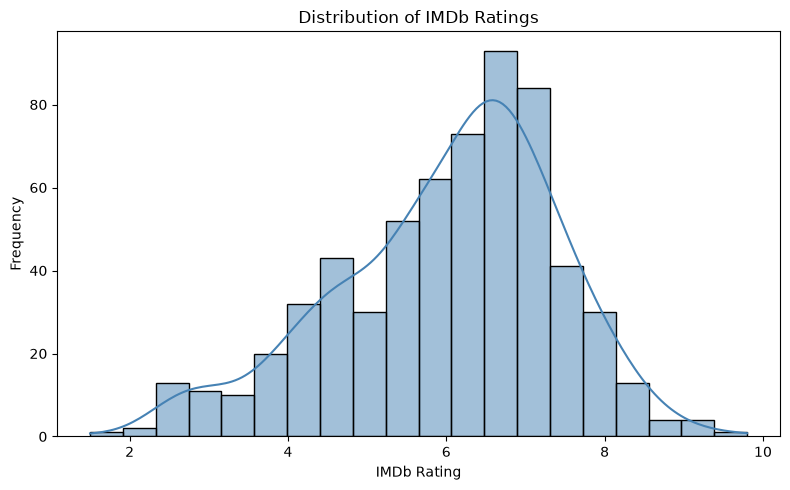

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df["averagerating"].dropna(),
    bins=20,
    kde=True,
    ax=ax,
    color="steelblue"
)

ax.set_title("Distribution of IMDb Ratings")
ax.set_xlabel("IMDb Rating")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Insight (rating distribution):** ratings are slightly left-skewed, with a peak between about 6.5 and 7.0 and most movies between roughly 5 and 7.5. Very low (below 3) and very high (above 9) ratings are rare, which is why the average (6.02) sits slightly below the median (6.3).

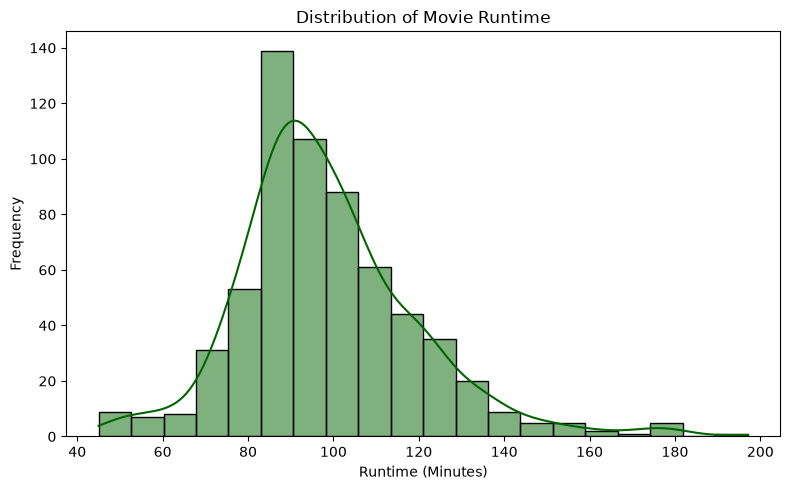

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df["runtimeminutes"].dropna(),
    bins=20,
    kde=True,
    ax=ax,
    color="darkgreen"
)

ax.set_title("Distribution of Movie Runtime")
ax.set_xlabel("Runtime (Minutes)")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Insight (runtime distribution):** runtime is right-skewed. The most common length is about 83–90 minutes (the tallest bar, roughly 140 movies), and most films run 80–120 minutes. A small tail of long films reaches about 180–197 minutes.

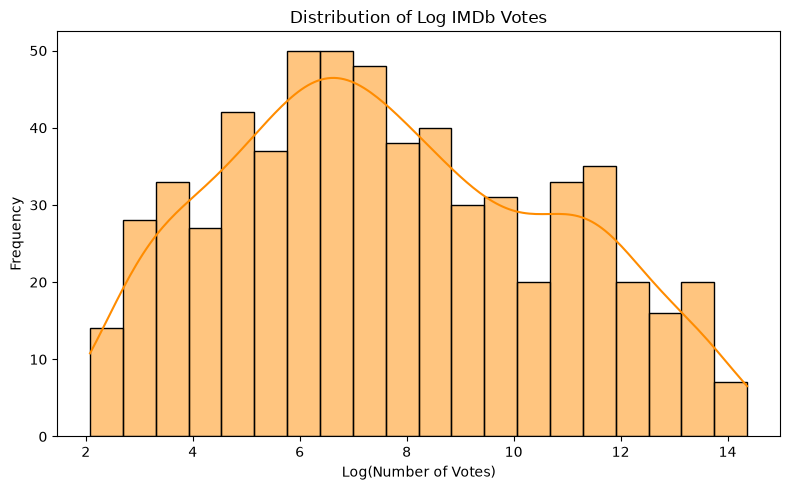

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df["log_votes"].dropna(),
    bins=20,
    kde=True,
    ax=ax,
    color="darkorange"
)

ax.set_title("Distribution of Log IMDb Votes")
ax.set_xlabel("Log(Number of Votes)")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Insight (log votes distribution):** on a log scale the votes spread widely, from about 7 votes (log value near 2) to over 1.7 million (near 14.4), with a second smaller bump near 11–12 (roughly 60,000–160,000 votes). This shows audience attention is very unequal across movies, and it justifies using the log transformation and medians instead of raw means.

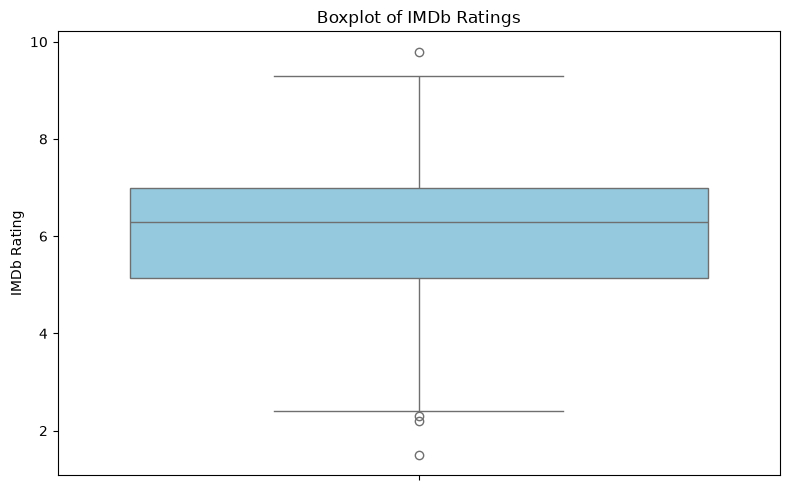

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    y=df["averagerating"].dropna(),
    ax=ax,
    color="skyblue"
)

ax.set_title("Boxplot of IMDb Ratings")
ax.set_ylabel("IMDb Rating")

plt.tight_layout()
plt.show()

**Insight (rating boxplot):** the median is 6.3 and the middle half of ratings lies between about 5.2 and 7.0. Several outliers fall below about 2.7 (lowest 1.5), and one very high outlier sits near 9.8. These are valid IMDb scores, so they were kept, but they are worth remembering when reading averages.

## Business Questions

Each analysis below answers one precise question using a simple groupby and chart. Under every chart, an **Insight** explains what it shows, and a **Caution** notes what it does not show.

### 1. Which years had the most Hollywood movie releases from 2016–2025?

In [18]:
movies_by_year = (
    df.groupby("startyear", as_index=False)
    .size()
    .rename(columns={"size": "movie_count"})
)

movies_by_year

,startyear,movie_count
0,2016.0,47
1,2017.0,54
2,2018.0,79
3,2019.0,158
4,2020.0,64
5,2021.0,61
6,2022.0,66
7,2023.0,48
8,2024.0,37
9,2025.0,34


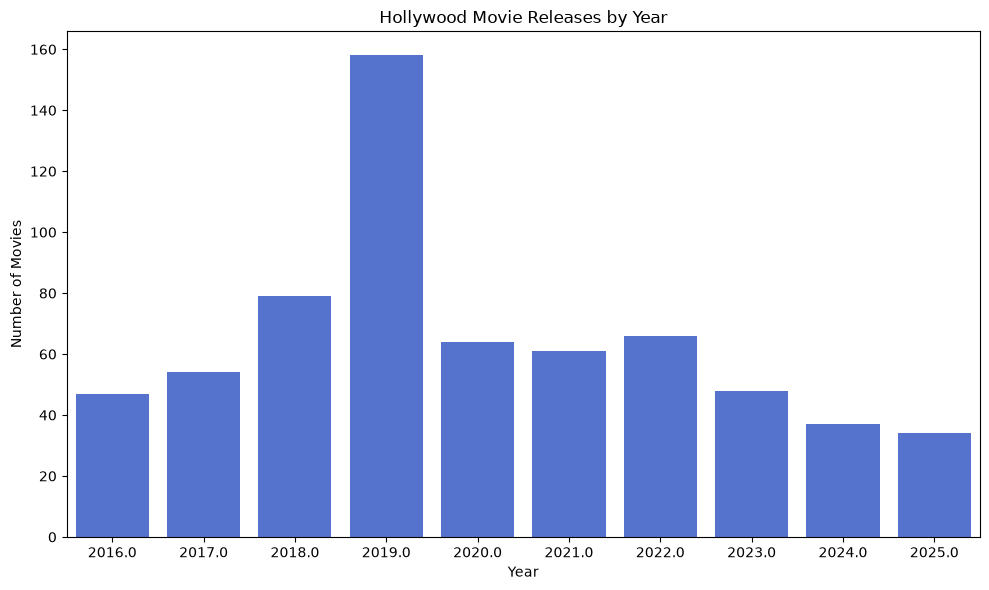

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=movies_by_year,
    x="startyear",
    y="movie_count",
    ax=ax,
    color="royalblue"
)

ax.set_title("Hollywood Movie Releases by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

Interpretation: this chart shows how the number of Hollywood-focused movies varied across the ten-year period.

**Insight:** 2019 is the clear peak with **158 movies (about 24% of all 647)**, followed by 2018 (80). Counts rise from 46 (2016) to 158 (2019), then fall back to 64 in 2020 and keep declining to 48 (2023), 37 (2024) and 34 (2025).

**Caution:** this is the number of movies *in this filtered dataset*, not industry output. A one-year jump to 158 and a steady drop in recent years are more likely to reflect how the US + English filter and IMDb's data coverage behave than a real production boom or slump.

### 2. Which 10 genres appeared most often in Hollywood movies?

In [20]:
genre_df = df.copy()

genre_df["genres"] = genre_df["genres"].fillna("Unknown")

genre_df = genre_df.assign(
    genre=genre_df["genres"].str.split(",")
)

genre_df = genre_df.explode("genre")

genre_df["genre"] = genre_df["genre"].str.strip()

genre_counts = (
    genre_df["genre"]
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = [
    "genre",
    "movie_count"
]

genre_counts

,genre,movie_count
0,Drama,245
1,Comedy,161
2,Action,116
3,Documentary,116
4,Thriller,111
5,Adventure,99
6,Horror,93
7,Crime,69
8,Mystery,56
9,Romance,55


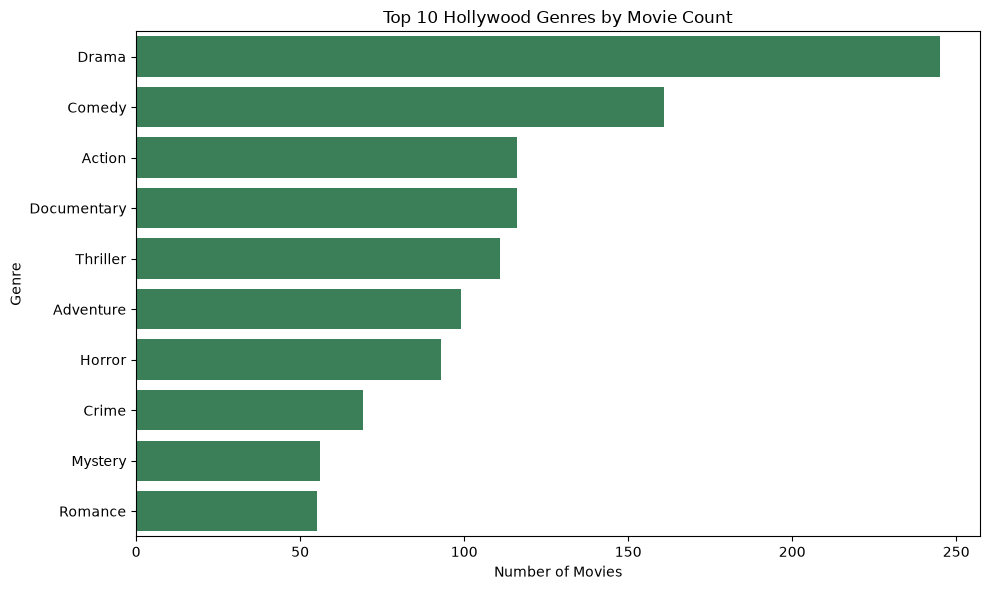

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=genre_counts,
    x="movie_count",
    y="genre",
    ax=ax,
    color="seagreen"
)

ax.set_title("Top 10 Hollywood Genres by Movie Count")
ax.set_xlabel("Number of Movies")
ax.set_ylabel("Genre")

plt.tight_layout()
plt.show()

Interpretation: the chart identifies the ten genres that occur most frequently in the Hollywood-focused dataset. A movie with multiple genres contributes to each of its listed genres.

**Insight:** **Drama (245)** is the most common genre, appearing in about 38% of movies, followed by **Comedy (161)**, Action (116), Documentary (115) and Thriller (108). Adventure (99), Horror (93), Crime (68), Mystery (56) and Romance (55) complete the top ten.

**Caution:** genre counts add up to more than 647 because one movie can carry up to three genres.

### 3. Which 5 genres have the highest average IMDb rating, considering only genres with at least 50 movies?

In [22]:
genre_rating = (
    genre_df
    .groupby("genre")
    .agg(
        movie_count=("tconst", "count"),
        average_rating=("averagerating", "mean")
    )
    .reset_index()
)

genre_rating = genre_rating[
    genre_rating["movie_count"] >= 50
]

genre_rating = (
    genre_rating
    .sort_values("average_rating", ascending=False)
    .head(5)
)

genre_rating

,genre,movie_count,average_rating
7,Documentary,116,7.122772
2,Adventure,99,6.259184
0,Action,116,6.099130
5,Comedy,161,6.049359
8,Drama,245,6.044167


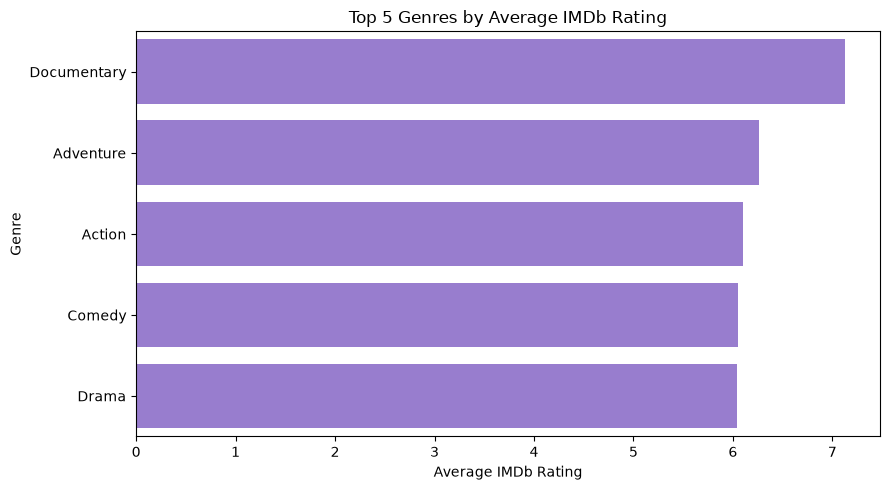

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=genre_rating,
    x="average_rating",
    y="genre",
    ax=ax,
    color="mediumpurple"
)

ax.set_title("Top 5 Genres by Average IMDb Rating")
ax.set_xlabel("Average IMDb Rating")
ax.set_ylabel("Genre")

plt.tight_layout()
plt.show()

Interpretation: using a minimum of 50 movies prevents a genre with only a few records from dominating the comparison.

**Insight:** **Documentary has the highest average rating (7.11)**, about 0.85 points above the next genre, Adventure (6.26). Action (6.10), Drama (6.05) and Comedy (6.05) are almost tied and sit close to the overall average of 6.02.

**Caution:** the gap for Documentary is large relative to the others, but a difference of means is not yet proof. Documentaries may be rated by a self-selected, interested audience; a significance test (for example Welch's t-test or Mann-Whitney U) would be the next step.

### 4. Did the average IMDb rating change across 2016–2025?

In [24]:
rating_by_year = (
    df.groupby("startyear", as_index=False)["averagerating"]
    .mean()
)

rating_by_year

,startyear,averagerating
0,2016.0,5.780000
1,2017.0,6.180769
2,2018.0,5.893590
3,2019.0,6.088079
4,2020.0,5.725806
5,2021.0,5.475439
6,2022.0,6.064516
7,2023.0,6.580952
8,2024.0,6.110811
9,2025.0,6.593939


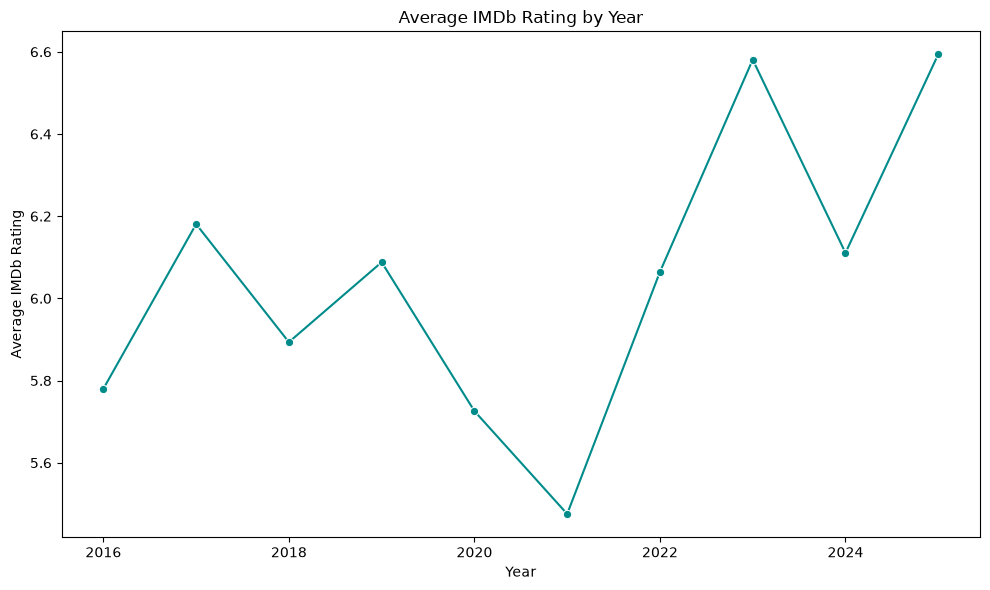

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=rating_by_year,
    x="startyear",
    y="averagerating",
    marker="o",
    ax=ax,
    color="darkcyan"
)

ax.set_title("Average IMDb Rating by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Average IMDb Rating")

plt.tight_layout()
plt.show()

Interpretation: this line chart shows the year-by-year movement in average IMDb ratings. It describes the trend but does not establish a cause for any change.

**Insight:** the yearly average stays in a narrow band between about **5.48 (2021, lowest)** and **6.60 (2023, highest)**. Ratings dip in 2020–2021 (5.74 and 5.48) and are higher in 2023 (6.60) and 2025 (6.50). There is no steady upward or downward trend.

**Caution:** the differences are small compared with the spread of individual ratings (standard deviation about 1.4), and some years have few movies (34–66), so single-year averages move easily. Recent years are also still collecting votes.

### 5. Which 10 movies received the highest number of IMDb votes?

In [26]:
most_voted_movies = (
    df[
        df["numvotes"].notna()
    ]
    .sort_values("numvotes", ascending=False)
    .head(10)
)

most_voted_movies[
    [
        "primarytitle",
        "startyear",
        "averagerating",
        "numvotes"
    ]
]

,primarytitle,startyear,averagerating,numvotes
519,Joker,2019.0,8.3,1734139.0
349,Avengers: Endgame,2019.0,8.4,1504167.0
348,Avengers: Infinity War,2018.0,8.4,1420859.0
123,Deadpool,2016.0,8.0,1277343.0
155,Oppenheimer,2023.0,8.2,1108926.0
31,Spider-Man: No Way Home,2021.0,8.1,1085075.0
183,The Batman,2022.0,7.8,955570.0
178,Black Panther,2018.0,7.3,931439.0
307,Thor: Ragnarok,2017.0,7.9,918768.0
336,Guardians of the Galaxy: Vol. 2,2017.0,7.6,851764.0


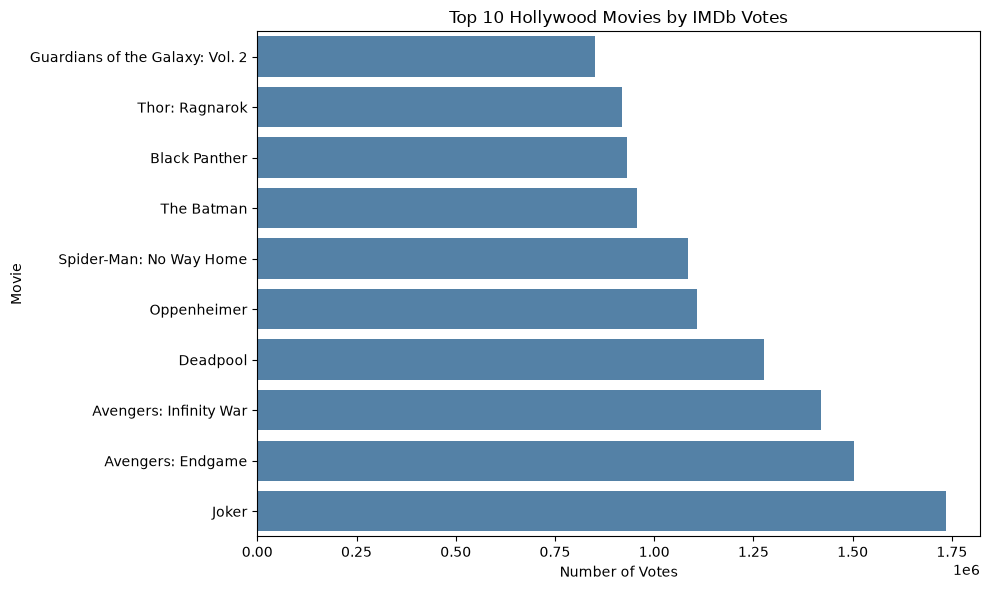

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = most_voted_movies.sort_values(
    "numvotes",
    ascending=True
)

sns.barplot(
    data=plot_data,
    x="numvotes",
    y="primarytitle",
    ax=ax,
    color="steelblue"
)

ax.set_title("Top 10 Hollywood Movies by IMDb Votes")
ax.set_xlabel("Number of Votes")
ax.set_ylabel("Movie")

plt.tight_layout()
plt.show()

Interpretation: vote count is used here as a simple measure of audience attention on IMDb. It should not be treated as a direct measure of movie quality.

**Insight:** **Joker (about 1.73M votes)**, Avengers: Endgame (1.49M), Avengers: Infinity War (1.41M), Deadpool (1.27M) and Oppenheimer (1.10M) lead the list. **Nine of the ten most-voted movies are comic-book or superhero films**; Oppenheimer is the exception. All ten were released between 2016 and 2023 and have ratings between 7.3 and 8.4, so very high attention goes together with good, but not perfect, ratings.

### 6. Which 10 movies have the highest IMDb ratings among movies with at least 10,000 votes?

In [28]:
top_rated_movies = (
    df[
        df["numvotes"].ge(10000)
    ]
    .sort_values("averagerating", ascending=False)
    .head(10)
)

top_rated_movies[
    [
        "primarytitle",
        "startyear",
        "averagerating",
        "numvotes"
    ]
]

,primarytitle,startyear,averagerating,numvotes
604,Jersey,2019.0,8.5,30831.0
366,Spider-Man: Into the Spider-Verse,2018.0,8.4,822660.0
349,Avengers: Endgame,2019.0,8.4,1504167.0
348,Avengers: Infinity War,2018.0,8.4,1420859.0
519,Joker,2019.0,8.3,1734139.0
505,Super Deluxe,2019.0,8.2,20486.0
155,Oppenheimer,2023.0,8.2,1108926.0
187,Ford v Ferrari,2019.0,8.1,591058.0
31,Spider-Man: No Way Home,2021.0,8.1,1085075.0
189,Still: A Michael J. Fox Movie,2023.0,8.1,18354.0


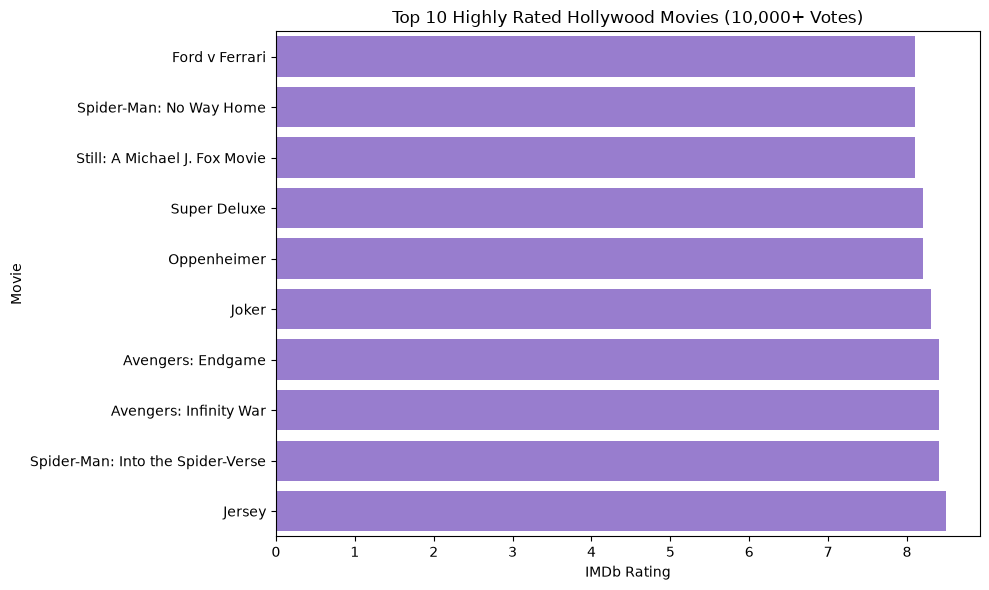

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = top_rated_movies.sort_values(
    "averagerating",
    ascending=True
)

sns.barplot(
    data=plot_data,
    x="averagerating",
    y="primarytitle",
    ax=ax,
    color="mediumpurple"
)

ax.set_title("Top 10 Highly Rated Hollywood Movies (10,000+ Votes)")
ax.set_xlabel("IMDb Rating")
ax.set_ylabel("Movie")

plt.tight_layout()
plt.show()

Interpretation: the minimum vote threshold makes the rating comparison more meaningful by excluding movies with very few IMDb votes.

**Insight:** the top rated movies are Jersey (8.5), then Spider-Man: Into the Spider-Verse, Avengers: Endgame and Avengers: Infinity War (8.4 each), and Joker (8.3). Most of the list are also among the most-voted movies, so crowd-pleasing, widely watched films dominate the high ratings.

**Caution:** *Jersey* (8.5) and *Super Deluxe* (8.2) are Indian-language films, which shows that the US + English title filter lets in some non-Hollywood movies. The 10,000-vote threshold removes tiny-sample ratings, but it cannot fix a loose definition of "Hollywood". Adding production country or original language would tighten it.

### 7. Does movie runtime show a relationship with IMDb rating?

In [30]:
runtime_rating_data = df[
    [
        "runtimeminutes",
        "averagerating"
    ]
].dropna()

runtime_rating_data.head(10)

,runtimeminutes,averagerating
0,122.0,7.3
1,107.0,7.0
2,100.0,5.7
3,96.0,5.9
4,122.0,7.1
5,106.0,5.8
6,93.0,8.5
7,109.0,3.9
8,90.0,4.8
9,117.0,5.7


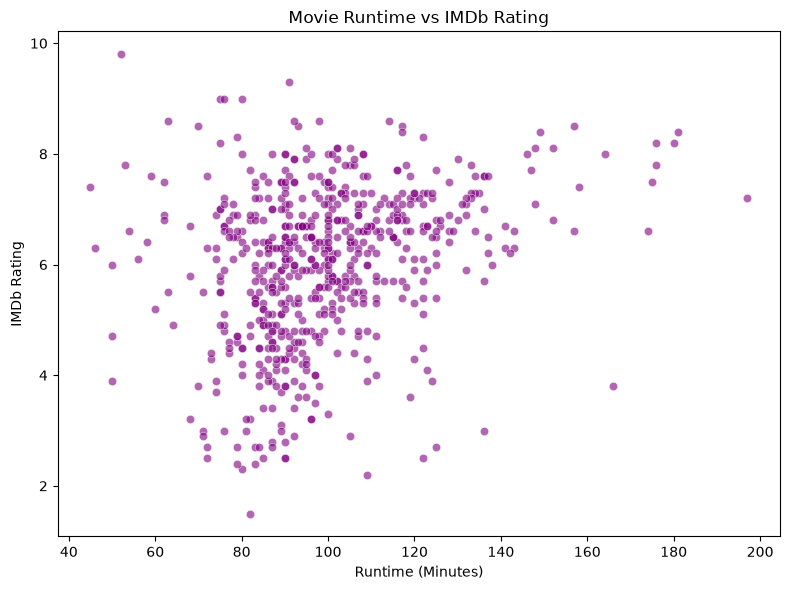

In [31]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=runtime_rating_data,
    x="runtimeminutes",
    y="averagerating",
    alpha=0.6,
    ax=ax,
    color="purple"
)

ax.set_title("Movie Runtime vs IMDb Rating")
ax.set_xlabel("Runtime (Minutes)")
ax.set_ylabel("IMDb Rating")

plt.tight_layout()
plt.show()

In [32]:
runtime_rating_data[
    [
        "runtimeminutes",
        "averagerating"
    ]
].corr()

,runtimeminutes,averagerating
runtimeminutes,1.000000,0.278254
averagerating,0.278254,1.000000


Interpretation: the scatter plot and correlation value show whether runtime and rating move together. Correlation describes association, not causation.

**Insight:** the correlation is **0.28**, a weak positive relationship (runtime explains only about 8% of the variation in rating, since 0.28 squared is about 0.08). In the scatter plot, most movies cluster between 80 and 120 minutes and show ratings from about 2 to 8 at the same runtime, so runtime alone does not predict a rating. Movies longer than about 140 minutes are few, but most of them are rated 6 or higher.

**Caution:** longer movies may simply be more ambitious dramas or franchise films watched by committed audiences; this EDA cannot separate those explanations.

### 8. Which 10 genres have the highest median IMDb vote count?

In [33]:
genre_votes = (
    genre_df
    .groupby("genre")["numvotes"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

genre_votes

,genre,numvotes
0,Adventure,75506.0
1,Action,43531.0
2,Animation,31544.0
3,Sci-Fi,21088.0
4,Mystery,15693.0
5,Fantasy,15199.5
6,Biography,9687.0
7,Crime,8691.0
8,Comedy,4677.0
9,History,3366.5


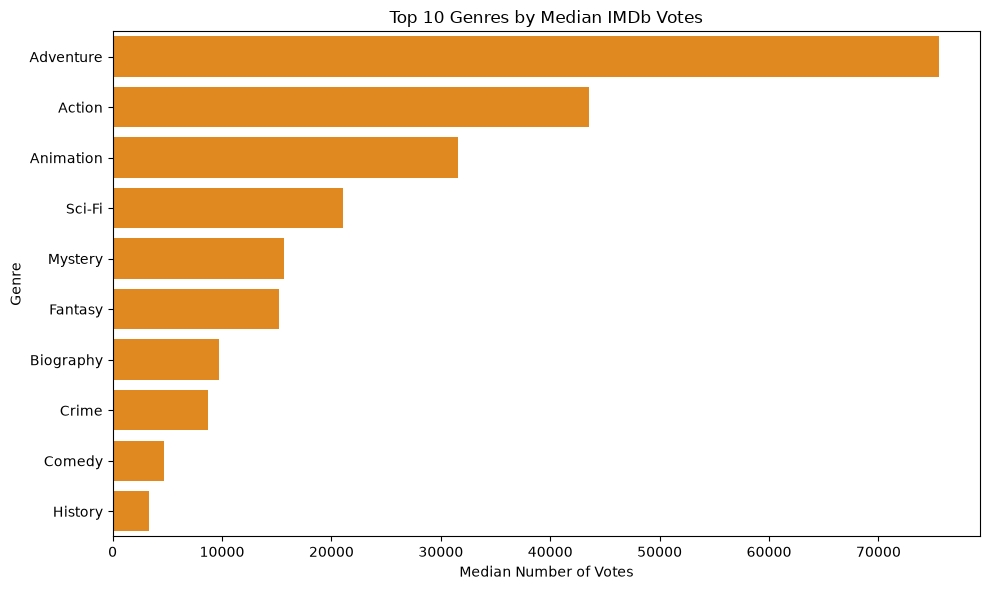

In [34]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=genre_votes,
    x="numvotes",
    y="genre",
    ax=ax,
    color="darkorange"
)

ax.set_title("Top 10 Genres by Median IMDb Votes")
ax.set_xlabel("Median Number of Votes")
ax.set_ylabel("Genre")

plt.tight_layout()
plt.show()

Interpretation: median vote count reduces the effect of a few extremely popular blockbuster movies and gives a clearer view of typical genre-level attention.

**Insight:** **Adventure has the highest median vote count (about 74,930)**, followed by Action (about 43,036), Animation (about 31,267), Sci-Fi (about 21,049) and Mystery (about 15,650). Comedy (about 4,636) and History (about 3,361) are at the bottom of the top ten.

**Takeaway:** frequent does not mean popular. Drama is the most common genre (Question 2) but does not appear in the top ten by median votes, while the big-budget, spectacle-oriented genres (Adventure, Action, Animation, Sci-Fi) attract the most audience attention for a typical movie.

## Correlation Analysis

The correlation matrix and heatmap summarise how runtime, rating and votes move together (Pearson correlation, from -1 to 1).

In [35]:
correlation = df[
    [
        "runtimeminutes",
        "averagerating",
        "numvotes"
    ]
].corr()

correlation

,runtimeminutes,averagerating,numvotes
runtimeminutes,1.000000,0.278254,0.468318
averagerating,0.278254,1.000000,0.299310
numvotes,0.468318,0.299310,1.000000


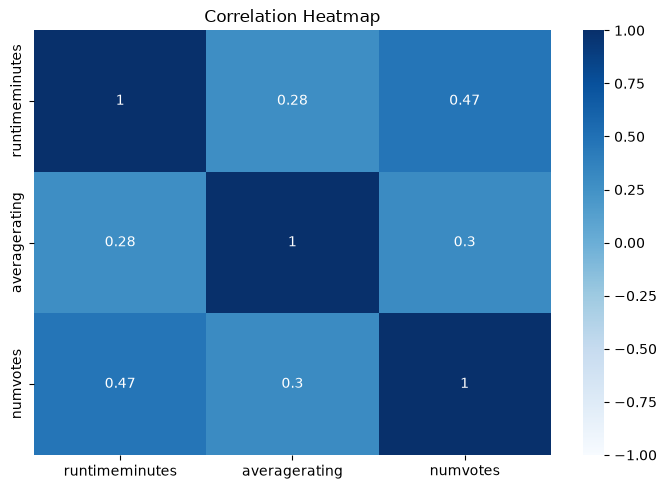

In [36]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

**Insight (correlation heatmap):** all three relationships are positive but not strong. The strongest is **runtime and votes (0.47)**, then **rating and votes (0.30)**, then **runtime and rating (0.28)**. Longer and better-rated movies tend to attract more votes, but no single variable explains the others.

**Caution:** votes are extremely skewed, so a few blockbusters can influence Pearson correlations involving votes. Spearman correlation or the `log_votes` column would be a more robust check.

## Final Conclusion

This EDA focuses only on Hollywood-oriented IMDb movie records from 2016 to 2025 (647 movies) and answers precise questions about yearly volume, genre frequency, genre ratings, rating trends, popularity, highly rated movies and runtime.

**Key findings**
- **Volume:** 2019 is the peak year (158 movies, about 24% of the dataset); counts decline after 2020 to 34 in 2025.
- **Genres:** Drama (245) and Comedy (161) are the most frequent genres.
- **Ratings:** Documentary has the highest average rating (7.11) among genres with at least 50 movies; ratings are centred around 6–7 (mean 6.02, median 6.3).
- **Trend:** average yearly rating moves between about 5.5 (2021) and 6.6 (2023) without a steady trend.
- **Popularity:** Joker, Avengers: Endgame and Infinity War lead on votes; Adventure and Action have the highest median votes.
- **Runtime:** longer movies are slightly better rated (r = 0.28) and receive more votes (r = 0.47), but runtime alone is a weak predictor.

**Limitations**
- "Hollywood" is a US + English title-alias proxy and includes some non-Hollywood films (for example *Jersey* and *Super Deluxe*).
- The dataset is small (647 movies), and year-to-year volume (especially the 2019 peak and the post-2020 decline) may reflect filtering and data coverage, not real production trends.
- IMDb ratings reflect the people who vote, not all viewers; recent movies are still collecting votes.
- There is no budget or box-office data, so "success" cannot be measured.
- All relationships are correlations, not causes.